# Predicting Stress Through Wearable Tech Data
## 01: Data Audit and Baseline

### Setup Imports

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

SEED = 136

### Loading and Auditing

In [29]:
df = pd.read_csv('../data/Wearable_Tech_Sleep_Stress_Dataset.csv')

print(df.shape)
print(df.dtypes)

(10000, 16)
User_ID                        str
Age                          int64
Gender                         str
Physical_Activity_Level        str
Diet_Type                      str
BMI                        float64
Caffeine_Intake_mg         float64
Water_Intake_liters        float64
Screen_Time_Hours          float64
Daily_Steps                  int64
Calories_Burned              int64
Resting_Heart_Rate         float64
Daily_Sleep_Hours          float64
Deep_Sleep_Hours           float64
Sleep_Quality_Score        float64
Daily_Stress_Level             str
dtype: object


This output shows the size of the data set (10,000 rows, 16 columns), and the different datatypes corresponding to each input feature

In [30]:
print(df.isna().sum())
print("\nDuplicate rows: ", df.duplicated().sum())

User_ID                      0
Age                          0
Gender                       0
Physical_Activity_Level      0
Diet_Type                    0
BMI                        210
Caffeine_Intake_mg         206
Water_Intake_liters          0
Screen_Time_Hours            0
Daily_Steps                  0
Calories_Burned              0
Resting_Heart_Rate         219
Daily_Sleep_Hours          190
Deep_Sleep_Hours             0
Sleep_Quality_Score          0
Daily_Stress_Level           0
dtype: int64

Duplicate rows:  0


This output counts missing values in each column. Wherever a 0 appears, there are no missing values in the column, wherever the value shows more than 0 there are values missing from the dataset that will need to be accounted for. This occurs in ```BMI```, ```Caffeine_Intake_mg```, ```Resting_Heart_Rate```, and ```Daily_Sleep_Hours```, hovering around 200 times in each case. About 8% of rows are affected, and 2% of total values.  
The output also shows no duplicated rows.

In [31]:
print("\n", df["Daily_Stress_Level"].value_counts(normalize=True))


 Daily_Stress_Level
Low       0.5789
Medium    0.3786
High      0.0425
Name: proportion, dtype: float64


This output shows a normalised view of people who reported low, medium, and high stress (the target variable). The classes are heavily imbalanced, so Macro-F1 will be used as the main metric. Roughly 58% of reports were for low stress, 38% medium, and 4% high.


                 Age          BMI  Caffeine_Intake_mg  Water_Intake_liters  \
count  10000.000000  9790.000000         9794.000000         10000.000000   
mean      43.539400    25.087406          207.365224             2.502550   
std       14.911636     3.905276          137.681368             0.802058   
min       18.000000    17.500000            0.000000             0.500000   
25%       31.000000    22.300000          100.000000             2.000000   
50%       43.000000    25.100000          201.000000             2.500000   
75%       56.000000    27.800000          303.000000             3.000000   
max       69.000000    38.000000          730.000000             5.000000   

       Screen_Time_Hours   Daily_Steps  Calories_Burned  Resting_Heart_Rate  \
count       10000.000000  10000.000000     10000.000000         9781.000000   
mean            7.060990   7963.857000      1573.986300           66.944177   
std             2.443689   4021.490815       320.153851            

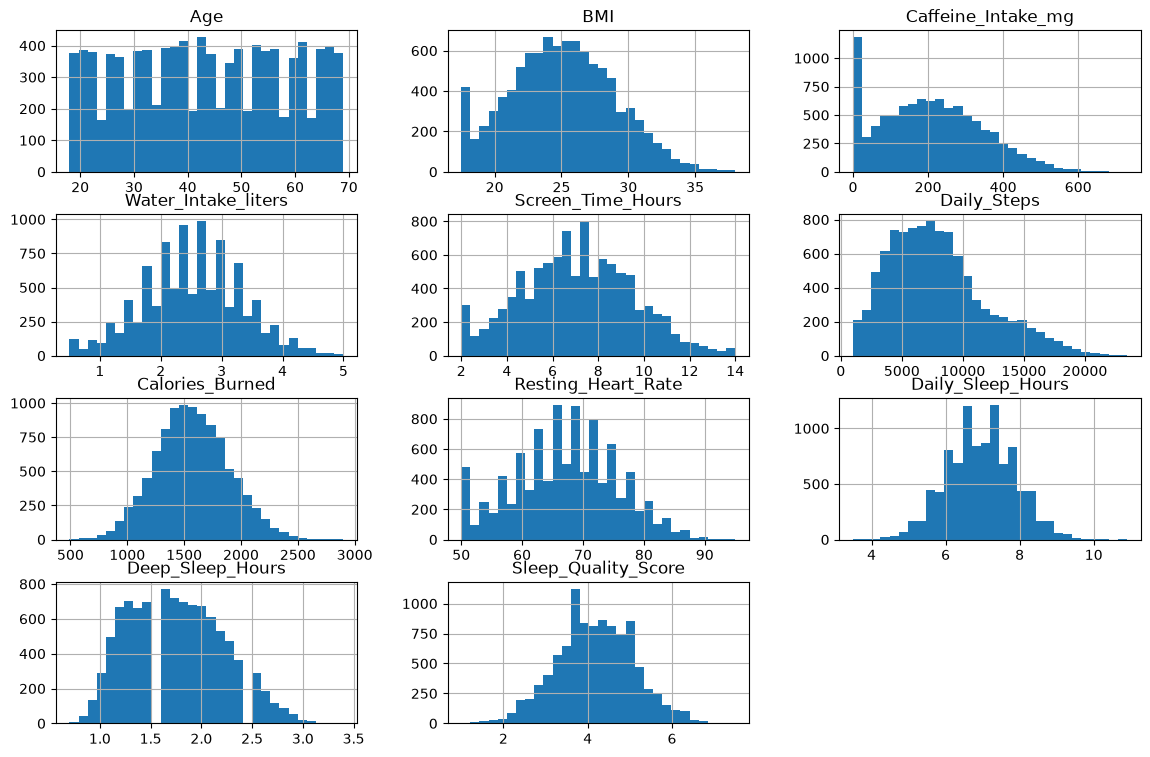

In [32]:
print("\n", df.describe())
df.hist(figsize=(14, 9), bins = 30)
plt.show()

This output plots histograms for every feature in the dataset.
In features such as ```BMI```, ```Caffeine_Intake_mg```, and ```Resting_Heart_Rate``` there is a clear increase in people reporting the lowest acceptable value. This could be due to people not drinking caffeine etc. or in cases such as resting heart rate, it could be due to the synthetic nature of the data, where a number is randomly generated and if it is below 50, it is set to 50.  
```Age``` also looks like a uniform spread with awkward looking drops roughly evenly spread, also pointing to synthetic data.

### Features, Target and Train/Test Split

In [33]:
target = "Daily_Stress_Level"
X = df.drop(columns=[target, "User_ID", "Sleep_Quality_Score"])
y = df[target]
print(X.shape)
print(y.shape)

(10000, 13)
(10000,)


Above, ```X``` holds the input features and ```y``` is what is predicted. ```X``` is created by dropping the target because it has no predictive meaning, and two other columns from the data, and ```y``` is the target column. ```Sleep_Quality_Score``` is dropped because it's recorded on the same day as stress, so it risks leakage. It may be tested later as a sensitivity check.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = SEED)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize = True))
print(y_test.value_counts(normalize = True))

(8000, 13) (2000, 13)
Daily_Stress_Level
Low       0.578875
Medium    0.378625
High      0.042500
Name: proportion, dtype: float64
Daily_Stress_Level
Low       0.5790
Medium    0.3785
High      0.0425
Name: proportion, dtype: float64


```test_size = 0.2``` gives an 80/20 split (8,000 rows / 2,000 rows) between training and testing data. ```stratify = y``` keeps the class proportions the same in both sections. That is important because the High stress level is only about 4% of the data. Using a seed for the ```random_state``` makes it reproducible which is hugely important because without a fixed seed, the split could change on every run and the results would not be able to be reproduced. We can see from the output that the two sections have very similar class proportions, indicating that this split could work.  
The test set (2,000 rows) is going to be used once, at the end, for final evaluation only. This prevents leakage where the model would be learning from the test set and then trying to predict it later, which could lead to a model that is only correct when predicting values it already knows.  
Model comparison and tuning will use stratified 5-fold cross-validation on the training set (8,000) rows only, which also avoids leakage and keeps the test set unseen.

### Preprocessing Pipeline

In [35]:
num_cols = X.select_dtypes(include = "number").columns.tolist()
cat_cols = X.select_dtypes(exclude = "number").columns.tolist()
print(num_cols)
print(cat_cols)

['Age', 'BMI', 'Caffeine_Intake_mg', 'Water_Intake_liters', 'Screen_Time_Hours', 'Daily_Steps', 'Calories_Burned', 'Resting_Heart_Rate', 'Daily_Sleep_Hours', 'Deep_Sleep_Hours']
['Gender', 'Physical_Activity_Level', 'Diet_Type']


This splits the columns by type. There are 10 numeric columns and 3 categorical ones (```Gender```, ```Physical_Activity_Level```, ```Diet_Type```).

In [37]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown = "ignore"))
])

preprocess = ColumnTransformer([
    ("numeric", numeric_pipe, num_cols),
    ("categorical", categorical_pipe, cat_cols)
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

Above I am using 2 pipelines to transform the data into a format that all models can use, as some models cannot use categorical data, and some other models will practically ignore smaller values, like ```BMI``` when larger values, such as ```Daily_Steps``` are present.  
The two ```SimpleImputer``` boxes fill missing values in the data, as some models can not function when there is data missing. The ```numeric``` ```SimpleImputer``` will fill in missing data with the median from the rest of the data across the column, so that it is not thrown off by outliers. The ```categorical``` ```SimpleImputer``` will replace missing data with the most frequent value from the rest of the data in the same column.  
```StandardScaler``` standardises numeric features to a common scale because all models can work with that, whereas some models are more sensitive to feature scale, so scaling them puts them on a comparable footing.  
```OneHotEncoder``` turns categorical features into binary columns so that models can use them.  
I have put this into a pipeline to prevent leakage. The imputation medians, scaling means, and encoder categories are learned from the training data only. In cross-validation each fold learns them from its own training part and applies them to the held-out part. Doing the preprocessing on the full dataset first would let the test set information leak into the training set and the scores seem better than they would be on a set that hasn't learned from test data.